<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_ap_robocup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio V, apêndice: futebol de robôs

## Rastrear quatro adversários com um sensor que não diz quem é quem: filtros de Kalman e o algoritmo húngaro

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Anterior:** [X5_dualcomplexos.ipynb](X5_dualcomplexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_dualcomplexos.ipynb))

**O problema.** Num jogo de futebol de robôs (a RoboCup), o nosso robô vê os quatro adversários com uma câmera. A câmera devolve, a cada décimo de segundo, uma lista de detecções: pontos no **referencial do robô**, com ruído. A lista não diz **quem é quem**: os adversários são iguais. Às vezes um deles não é detectado (está atrás de outro, ou a detecção falhou), e às vezes aparece uma detecção falsa (um reflexo, um pé da arquibancada).

Para rastrear os quatro, há duas tarefas encadeadas:
1. **Mudar de referencial.** A detecção $z$ está no referencial do robô; no mundo, ela é $q\cdot z$ (a função `aplica`), com $q$ a pose do nosso robô, um dual-complexo. Aqui a pose é conhecida (ela viria de um filtro como o do notebook V(d)).
2. **Associar.** Decidir qual detecção vai para qual adversário, antes de atualizar o filtro de Kalman de cada um. Errar a associação é pior que perder uma medida: o filtro do adversário A passa a seguir o B, e não percebe.

**A associação como um problema de alocação.** Cada par (rastro $i$, detecção $j$) tem um custo, a **distância de Mahalanobis** ao quadrado, $d_{ij}^2=\boldsymbol\nu^\top\mathbf S^{-1}\boldsymbol\nu$, com $\boldsymbol\nu$ a inovação e $\mathbf S$ a sua covariância (o mesmo NIS dos notebooks de Kalman). Pares com $d^2$ acima de um limiar (a **janela de validação**, do qui-quadrado) são proibidos. A melhor associação é a que minimiza o custo total, com cada rastro recebendo no máximo uma detecção e vice-versa: o **problema de alocação**, que o **algoritmo húngaro** (Kuhn, 1955) resolve exatamente em tempo polinomial (`scipy.optimize.linear_sum_assignment`). A alternativa ingênua, o **vizinho mais próximo guloso** (pegar o par mais barato, retirá-lo, repetir), é mais simples e às vezes erra.

**O que este notebook mostra.**
1. O húngaro dá, a cada passo, custo total menor ou igual ao do guloso (conferido em todos os passos) e igual ao da busca exaustiva.
2. Num cenário com dois adversários que se cruzam, quantas vezes cada método **troca as identidades** (numa semente escolhida para mostrar uma diferença, e dita como tal).
3. Uma comparação em várias simulações.

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

from itertools import permutations
from scipy.optimize import linear_sum_assignment

def wrap(a):
    return np.pi - (np.pi - np.asarray(a, float)) % (2 * np.pi)

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

class DC:
    """Número dual-complexo q = a + b·ε, com a = a0 + i·a1 e b = b0 + i·b1, e a regra z·ε = ε·z̄.
    Guardado como quatro reais (a0, a1, b0, b1), que podem ser floats, Fractions ou números duais."""
    def __init__(self, a0, a1, b0, b1):
        self.a0, self.a1, self.b0, self.b1 = a0, a1, b0, b1
    def __mul__(self, o):
        if not isinstance(o, DC):                       # número real vezes dual-complexo
            return DC(self.a0 * o, self.a1 * o, self.b0 * o, self.b1 * o)
        # a = a1·a2 ;  b = a1·b2 + b1·conj(a2)   (a regra z ε = ε z̄ conjuga o fator que "passa" por ε)
        a0 = self.a0 * o.a0 - self.a1 * o.a1
        a1 = self.a0 * o.a1 + self.a1 * o.a0
        b0 = (self.a0 * o.b0 - self.a1 * o.b1) + (self.b0 * o.a0 + self.b1 * o.a1)
        b1 = (self.a0 * o.b1 + self.a1 * o.b0) + (self.b1 * o.a0 - self.b0 * o.a1)
        return DC(a0, a1, b0, b1)
    __rmul__ = __mul__
    def __add__(self, o): return DC(self.a0 + o.a0, self.a1 + o.a1, self.b0 + o.b0, self.b1 + o.b1)
    def __sub__(self, o): return DC(self.a0 - o.a0, self.a1 - o.a1, self.b0 - o.b0, self.b1 - o.b1)
    def conj(self):
        """q* = ā − b ε: o inverso de um dual-complexo unitário."""
        return DC(self.a0, -self.a1, -self.b0, -self.b1)
    def norma2(self):
        """q q* = |a|² (um número real: a parte dual se cancela)."""
        return self.a0 * self.a0 + self.a1 * self.a1
    @property
    def a(self): return complex(self.a0, self.a1)
    @property
    def b(self): return complex(self.b0, self.b1)
    def __repr__(self): return f"({self.a:.6g}) + ({self.b:.6g})ε"

def pose(theta, t):
    """A pose 'girar θ, transladar t' (t complexo): q = r + (t r̄ / 2) ε, com r = e^{iθ/2}."""
    r = np.exp(0.5j * theta); b = t * np.conj(r) / 2
    return DC(r.real, r.imag, b.real, b.imag)

def angulo(q):
    return float(wrap(2 * np.arctan2(q.a1, q.a0)))

def translacao(q):
    """t = 2 b a / |a|² (vale também para q não unitário)."""
    return 2 * q.b * q.a / q.norma2()

def aplica(q, p):
    """O ponto p (complexo) levado pela pose q: a translação de q · (translação até p)."""
    return translacao(q * pose(0.0, p))

def Exp(w, v):
    """Velocidade (ω, v) no corpo, v complexo, por uma unidade de tempo: um arco de círculo (ou um segmento, se ω = 0)."""
    return pose(w, v * np.exp(0.5j * w) * sinc(w / 2))

def Log(q):
    th = angulo(q)
    return th, translacao(q) / (np.exp(0.5j * th) * sinc(th / 2))

DT, SIG_Z, P_DET, LAMBDA_FALSO = 0.1, 0.15, 0.9, 0.5
CAMPO = (4.5, 3.0)                                        # meio-comprimento e meia-largura do campo (m)
JANELA = 9.21                                             # qui-quadrado com 2 graus de liberdade, 99%
F = np.block([[np.eye(2), DT * np.eye(2)], [np.zeros((2, 2)), np.eye(2)]])
H = np.hstack([np.eye(2), np.zeros((2, 2))])
QA, AMORT = 0.3, 0.97                                     # densidade espectral da aceleração (m²/s³) e amortecimento da velocidade
QF = 1.0                                                  # o filtro usa um ruído de processo maior que o da verdade: as curvas perto das linhas são manobras
Q = QF * np.block([[DT**3 / 3 * np.eye(2), DT**2 / 2 * np.eye(2)], [DT**2 / 2 * np.eye(2), DT * np.eye(2)]])
R = SIG_Z**2 * np.eye(2)

def adversarios_verdadeiros(rng, T=200, cruzamento=True):
    """Quatro adversários com velocidade aleatória suave, que freiam e voltam perto das linhas do campo.
    Com cruzamento=True, os dois primeiros começam em rota de colisão (passam a 20 cm um do outro)."""
    if cruzamento:
        x = np.array([[-2.0, 0.1, 1.0, 0.0], [2.0, -0.1, -1.0, 0.0], [-1, -2, 0.3, 0.4], [1, 2, -0.3, -0.4]], float)
    else:
        x = np.column_stack([rng.uniform(-3, 3, 4), rng.uniform(-2, 2, 4), rng.normal(0, 0.7, (4, 2))])
    hist = [x.copy()]
    for k in range(T):
        if not (cruzamento and k < 25):                   # no cruzamento, os primeiros 2,5 s são em linha reta
            x[:, 2:] = AMORT * x[:, 2:] + rng.normal(0, np.sqrt(QA * DT), (4, 2))
        for e in range(2):                                # perto da linha, o robô freia e volta (uma "mola" a 0,8 m da linha)
            dentro = CAMPO[e] - 0.8
            excesso = np.sign(x[:, e]) * np.maximum(np.abs(x[:, e]) - dentro, 0)
            x[:, e + 2] -= 3.0 * excesso * DT
        x[:, :2] += x[:, 2:] * DT
        hist.append(x.copy())
    return np.array(hist)

def pose_robo(k):
    """O nosso robô anda num círculo de 1 m no meio do campo, girando."""
    t = k * DT
    return pose(0.5 * t + np.pi / 2, np.exp(0.5j * t))

def detecta(rng, verdade_k, q):
    """A câmera: cada adversário detectado com probabilidade P_DET, no referencial do robô, com ruído; mais falsos positivos."""
    zs = []
    for p in verdade_k[:, 0] + 1j * verdade_k[:, 1]:
        if rng.random() < P_DET:
            zs.append(aplica(q.conj(), p) + SIG_Z * (rng.standard_normal() + 1j * rng.standard_normal()))
    for _ in range(rng.poisson(LAMBDA_FALSO)):
        zs.append(aplica(q.conj(), complex(rng.uniform(-CAMPO[0], CAMPO[0]), rng.uniform(-CAMPO[1], CAMPO[1]))))
    rng.shuffle(zs)                                        # a câmera não diz quem é quem
    return zs

## 1. As duas associações, e uma conferência por força bruta

O guloso e o húngaro recebem a mesma matriz de custos (rastros nas linhas, detecções nas colunas). Pares fora da janela recebem custo proibitivo. Para que um rastro possa ficar sem medida, o húngaro recebe uma coluna **fictícia** para cada rastro, com custo igual ao limiar da janela: ficar sem medida custa o mesmo que a pior medida aceitável. É o truque padrão para alocações em que nem todos precisam ser atendidos.

In [2]:
PROIBIDO = 1e6

def guloso(C):
    C = C.copy(); pares = []
    while True:
        i, j = np.unravel_index(np.argmin(C), C.shape)
        if C[i, j] >= JANELA: break
        pares.append((int(i), int(j))); C[i, :] = np.inf; C[:, j] = np.inf
    return pares

def hungaro(C):
    n, m = C.shape
    # colunas "fictícias": o rastro i pode ficar sem medida pagando o limiar da janela (só a sua própria coluna fictícia)
    ficticias = np.full((n, n), PROIBIDO); np.fill_diagonal(ficticias, JANELA)
    A = np.hstack([np.where(C < JANELA, C, PROIBIDO), ficticias])
    linhas, colunas = linear_sum_assignment(A)
    return [(int(i), int(j)) for i, j in zip(linhas, colunas) if j < m and C[i, j] < JANELA]

def custo(C, pares):
    """custo total, contando cada rastro sem medida como se pagasse o limiar da janela (assim os dois métodos são comparáveis)"""
    return sum(C[i, j] for i, j in pares) + JANELA * (C.shape[0] - len(pares))

def forca_bruta(C):
    n, m = C.shape; melhor = np.inf
    colunas = list(range(m)) + [None] * n                  # None: o rastro fica sem medida
    for perm in set(permutations(colunas, n)):
        pares = [(i, j) for i, j in enumerate(perm) if j is not None]
        if all(C[i, j] < JANELA for i, j in pares):
            melhor = min(melhor, custo(C, pares))
    return melhor

# um exemplo pequeno, de propósito armadilhado: o guloso pega o par (0,0), que é o mais barato, e estraga o resto
C = np.array([[1.0, 1.5, 50.0], [1.2, 8.0, 50.0], [50.0, 50.0, 2.0]])
print("guloso:", guloso(C), " custo", custo(C, guloso(C)))
print("húngaro:", hungaro(C), " custo", custo(C, hungaro(C)))
confere("o húngaro acha o ótimo da força bruta (exemplo armadilhado)", custo(C, hungaro(C)), forca_bruta(C))
rng = np.random.default_rng(7)
for _ in range(200):
    C = rng.exponential(4.0, (4, rng.integers(2, 6)))
    assert abs(custo(C, hungaro(C)) - forca_bruta(C)) < 1e-9
confere("e também em 200 matrizes aleatórias", True, True)

guloso: [(0, 0), (2, 2), (1, 1)]  custo 11.0
húngaro: [(0, 1), (1, 0), (2, 2)]  custo 4.7
OK   o húngaro acha o ótimo da força bruta (exemplo armadilhado):  diferença máxima = 0.00e+00
OK   e também em 200 matrizes aleatórias:  diferença máxima = 0.00e+00


## 2. O rastreador

Um filtro de Kalman de velocidade constante (o do Pepé, em duas dimensões) para cada adversário. A cada passo: predizer os quatro, levar as detecções ao mundo pela pose do robô, montar a matriz de Mahalanobis, associar, e atualizar cada rastro que recebeu uma detecção. Os rastros começam nas posições verdadeiras, para isolar o problema da associação (criar e apagar rastros é outra história).

In [3]:
def rastreia(verdade, metodo, semente):
    rng = np.random.default_rng(semente)
    T = len(verdade) - 1
    xs = [np.array([*verdade[0, i, :2], 0, 0]) for i in range(4)]
    Ps = [np.diag([0.1, 0.1, 1.0, 1.0]) for _ in range(4)]
    est = [np.array([x[:2] for x in xs])]
    custo_passos = []
    for k in range(1, T + 1):
        q = pose_robo(k)
        zs_mundo = [aplica(q, z) for z in detecta(rng, verdade[k], q)]
        xs = [F @ x for x in xs]; Ps = [F @ P @ F.T + Q for P in Ps]
        C = np.full((4, max(len(zs_mundo), 1)), np.inf)
        Ss = [H @ P @ H.T + R for P in Ps]
        for i in range(4):
            for j, z in enumerate(zs_mundo):
                nu = np.array([z.real, z.imag]) - H @ xs[i]
                C[i, j] = nu @ np.linalg.solve(Ss[i], nu)
        pares = metodo(C) if zs_mundo else []
        g, h = (guloso(C), hungaro(C)) if zs_mundo else ([], [])
        custo_passos.append((custo(C, g) if zs_mundo else 4 * JANELA, custo(C, h) if zs_mundo else 4 * JANELA,
                             set(g) != set(h)))      # os dois métodos discordam neste passo?
        for i, j in pares:
            z = np.array([zs_mundo[j].real, zs_mundo[j].imag])
            K = Ps[i] @ H.T @ np.linalg.inv(Ss[i])
            xs[i] = xs[i] + K @ (z - H @ xs[i]); Ps[i] = (np.eye(4) - K @ H) @ Ps[i]
        est.append(np.array([x[:2] for x in xs]))
    return np.array(est), np.array(custo_passos)

def trocas(verdade, est):
    """Quantas vezes, ao longo do tempo, algum rastro passa a ficar mais perto de outro adversário que do seu (com 0,5 m de folga)."""
    n = 0; dono = list(range(4))
    for k in range(len(est)):
        for i in range(4):
            d = np.linalg.norm(verdade[k, :, :2] - est[k, i], axis=1)
            if dono[i] != np.argmin(d) and d[np.argmin(d)] + 0.5 < d[dono[i]]:
                dono[i] = int(np.argmin(d)); n += 1
    return n, dono

verdade = adversarios_verdadeiros(np.random.default_rng(3), cruzamento=True)
d01 = np.linalg.norm(verdade[:, 0, :2] - verdade[:, 1, :2], axis=1)
print(f"os adversários 0 e 1 passam a {d01.min() * 100:.0f} cm um do outro, no passo {d01.argmin()}")
resultados = {}
for nome, metodo in [("guloso", guloso), ("húngaro", hungaro)]:
    est, cp = rastreia(verdade, metodo, semente=0)
    n, dono = trocas(verdade, est)
    erro = np.sqrt(np.mean(np.sum((est - verdade[:, :, :2])**2, axis=2)))
    resultados[nome] = (est, cp)
    print(f"{nome:8s}: {n} trocas de identidade; no fim, o rastro i segue o adversário {dono};  erro RMS contra o dono original {erro:.2f} m")
cp = resultados["húngaro"][1]
print(f"nos passos do rastreador húngaro, o guloso teria escolhido outra associação em {cp[:, 2].sum():.0f} de {len(cp)} passos")
confere("em todos os passos, o custo do húngaro ≤ o do guloso", np.all(cp[:, 1] <= cp[:, 0] + 1e-9), True)

os adversários 0 e 1 passam a 20 cm um do outro, no passo 20
guloso  : 5 trocas de identidade; no fim, o rastro i segue o adversário [2, 0, 3, 1];  erro RMS contra o dono original 2.84 m


húngaro : 0 trocas de identidade; no fim, o rastro i segue o adversário [0, 1, 2, 3];  erro RMS contra o dono original 0.15 m
nos passos do rastreador húngaro, o guloso teria escolhido outra associação em 7 de 200 passos
OK   em todos os passos, o custo do húngaro ≤ o do guloso:  diferença máxima = 0.00e+00


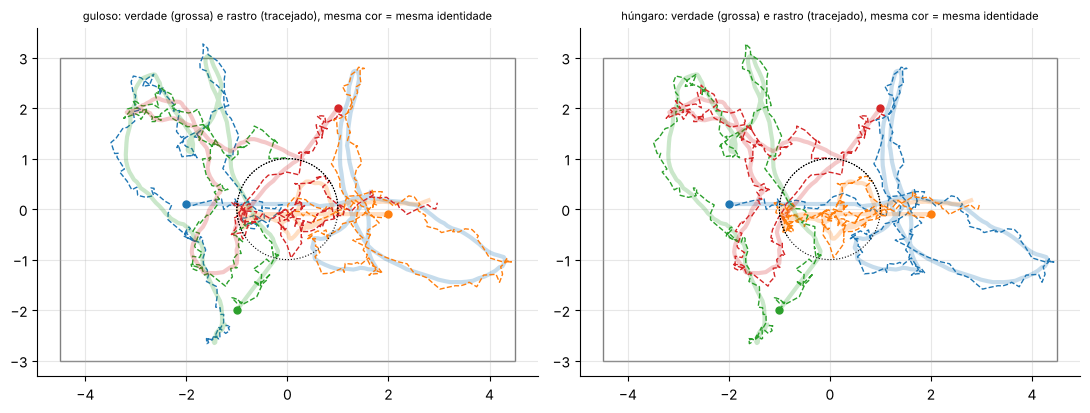

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, nome in zip(axs, ["guloso", "húngaro"]):
    est = resultados[nome][0]
    ax.add_patch(plt.Rectangle((-CAMPO[0], -CAMPO[1]), 2 * CAMPO[0], 2 * CAMPO[1], fill=False, ec="0.5"))
    for i in range(4):
        ax.plot(verdade[:, i, 0], verdade[:, i, 1], "-", color=f"C{i}", lw=3, alpha=0.25)
        ax.plot(est[:, i, 0], est[:, i, 1], "--", color=f"C{i}", lw=1)
        ax.plot(*verdade[0, i, :2], "o", color=f"C{i}", ms=5)
    robo = np.array([translacao(pose_robo(k)) for k in range(len(verdade))])
    ax.plot(robo.real, robo.imag, "k:", lw=0.8)
    ax.set_aspect("equal"); ax.set_title(f"{nome}: verdade (grossa) e rastro (tracejado), mesma cor = mesma identidade", fontsize=8)
plt.tight_layout(); plt.show()

## 3. Várias simulações

Um cenário só não diz muito: o resultado depende da sorte das detecções. Abaixo, 40 simulações de 20 s, com adversários em posições e velocidades aleatórias, mais o cenário do cruzamento com 40 sementes diferentes para a câmera.

In [5]:
tabela = {}
for cenario in ["aleatório", "cruzamento"]:
    soma = {"guloso": [0, 0.0], "húngaro": [0, 0.0]}; discorda = []
    for s in range(40):
        verdade = adversarios_verdadeiros(np.random.default_rng(100 + s), cruzamento=(cenario == "cruzamento"))
        for nome, metodo in [("guloso", guloso), ("húngaro", hungaro)]:
            est, cp = rastreia(verdade, metodo, semente=500 + s)
            if nome == "húngaro": discorda.append(cp[:, 2].mean())
            n, _ = trocas(verdade, est)
            soma[nome][0] += n; soma[nome][1] += n > 0
            soma[nome].append(np.linalg.norm(est - verdade[:, :, :2], axis=2).max() > 2)   # algum rastro se perdeu (> 2 m)?
    tabela[cenario] = soma
    print(f"cenário {cenario:10s}:  guloso {soma['guloso'][0]:3d} trocas, em {int(soma['guloso'][1]):2d} de 40 simulações;   "
          f"húngaro {soma['húngaro'][0]:3d} trocas, em {int(soma['húngaro'][1]):2d} de 40;   os métodos discordam em {100 * np.mean(discorda):.1f}% dos passos")
    print(f"      simulações em que algum rastro se afasta mais de 2 m do seu adversário: guloso {sum(soma['guloso'][2:])}, húngaro {sum(soma['húngaro'][2:])}")

cenário aleatório :  guloso  75 trocas, em 23 de 40 simulações;   húngaro  31 trocas, em 12 de 40;   os métodos discordam em 1.8% dos passos
      simulações em que algum rastro se afasta mais de 2 m do seu adversário: guloso 23, húngaro 12


cenário cruzamento:  guloso  59 trocas, em 22 de 40 simulações;   húngaro  46 trocas, em 16 de 40;   os métodos discordam em 1.6% dos passos
      simulações em que algum rastro se afasta mais de 2 m do seu adversário: guloso 20, húngaro 15


**Leitura.** No exemplo armadilhado, o guloso pega o par mais barato, (0, 0), e obriga o rastro 1 a ficar com uma detecção cara: custo 11,0 contra 4,7 do húngaro. Em 200 matrizes aleatórias, o húngaro (com as colunas fictícias) acerta o ótimo da força bruta todas as vezes, e no rastreador o seu custo nunca passou o do guloso.

No rastreador, os dois métodos discordam em poucos passos, menos de 2% deles: na maior parte do tempo os adversários estão longe uns dos outros, cada detecção cai na janela de um rastro só, e qualquer método acerta. Mas é justamente nesses poucos passos que se decide se um rastro troca de dono. Na figura, com a semente 0 da câmera, o guloso troca identidades cinco vezes e termina com os quatro rastros nos adversários errados; o húngaro não troca nenhuma. Isso **não** acontece sempre: em outras sementes, o húngaro é que troca e o guloso não, porque, quando dois adversários passam a 20 cm um do outro com um ruído de 15 cm, nenhuma associação pode ter certeza, e a "melhor" associação de um passo pode ser a errada.

A estatística das 40 simulações é que separa os dois. No cenário aleatório, o húngaro tem menos da metade das trocas do guloso (31 contra 75) e perde algum rastro em 12 simulações, contra 23. No cenário do cruzamento, a vantagem existe, mas é menor (46 contra 59 trocas). Em todos os casos, a maior parte das trocas vem de rastros que se perdem: um adversário que freia perto da linha, duas ou três detecções perdidas seguidas, e o rastro sai da janela; quando volta a encontrar uma detecção, pode ser a de outro. Criar e apagar rastros, que este notebook deixou de fora, é a outra metade do problema.

## Exercícios

1. **A janela.** Troque o limiar de 99% (9,21) por 95% (5,99) e por 99,9% (13,8). O que acontece com as trocas e com as medidas perdidas?
2. **Associação probabilística.** Em vez de escolher uma detecção, o JPDA (*Joint Probabilistic Data Association*) atualiza cada rastro com uma média das detecções compatíveis, ponderada pela probabilidade de cada associação. Implemente-o para dois rastros e compare no cenário do cruzamento.
3. **A pose incerta.** Até aqui a pose do robô era exata. Some um erro de 3° na orientação usada para levar as detecções ao mundo. Os quatro rastros erram juntos, na mesma direção: por quê? (Pense na matriz $\mathrm{Ad}_q$ do notebook V(c), seção 5.)